# AI Foundations — Experiments

## Expected Utility — Stok kararı simülasyonu

[theory.md](theory.md) Bölüm 4'teki problem:

$$a^* = \arg\max_{a \in A} \sum_{s \in S} P(s \mid e)\, U(a, s)$$

In [6]:
import numpy as np

states = ["Düşük", "Orta", "Yüksek"]
actions = ["Az", "Orta", "Çok"]

# U(a, s): satırlar = sipariş stratejisi, sütunlar = talep durumu (₺)
U = np.array([
    [ 10_000,  8_000,  3_000],
    [  4_000, 15_000, 12_000],
    [-10_000, 10_000, 25_000],
])


def tl(x):
    """Türkçe para formatı: 12650 -> '12.650 ₺'"""
    return f"{x:,.0f} ₺".replace(",", ".")


def decide(p):
    """p = [P(Düşük), P(Orta), P(Yüksek)] -> (beklenen kârlar, optimal eylem)"""
    p = np.asarray(p, dtype=float)
    if np.any(p < 0) or not np.isclose(p.sum(), 1.0):
        raise ValueError(f"Geçersiz olasılık dağılımı: {p} (negatif olamaz, toplam 1 olmalı)")
    eu = U @ p
    return eu, actions[int(np.argmax(eu))]


def report(p):
    eu, best = decide(p)
    print("Olasılıklar: " + ", ".join(f"{s} %{100 * q:.0f}" for s, q in zip(states, p)))
    for a, v in zip(actions, eu):
        print(f"  {a:<5} {tl(v):>10}" + ("  <- optimal" if a == best else ""))
    print()


### Senaryo A ve B

In [7]:
report([0.20, 0.50, 0.30])  # Senaryo A -> Orta
report([0.13, 0.52, 0.35])  # Senaryo B -> Çok


Olasılıklar: Düşük %20, Orta %50, Yüksek %30
  Az       6.900 ₺
  Orta    11.900 ₺  <- optimal
  Çok     10.500 ₺

Olasılıklar: Düşük %13, Orta %52, Yüksek %35
  Az       6.510 ₺
  Orta    12.520 ₺
  Çok     12.650 ₺  <- optimal



### Karar sınırı

P(Orta) = 0,5 sabitken P(Yüksek) = $h$ arttıkça optimal karar nerede değişiyor?

$p = [0{,}5 - h,\ 0{,}5,\ h]$ için beklenen kârlar $h$'ye göre doğrusal:

- $EU(\text{Orta}) = 9.500 + 8.000h$
- $EU(\text{Çok}) = 35.000h$

İkisi $h^* = 9.500 / 27.000 \approx 0{,}352$ noktasında eşitleniyor.

In [8]:
# Her eylemin EU'su h'nin doğrusal fonksiyonu: EU(h) = c0 + c1*h
p0 = np.array([0.5, 0.5, 0.0])     # h = 0
dp = np.array([-1.0, 0.0, 1.0])    # h arttıkça değişim yönü
c0, c1 = U @ p0, U @ dp

i_mid, i_high = actions.index("Orta"), actions.index("Çok")
h_star = (c0[i_mid] - c0[i_high]) / (c1[i_high] - c1[i_mid])
print(f"Karar sınırı: P(Yüksek) = {h_star:.4f}  (~%{100 * h_star:.1f})\n")

for h in np.linspace(0.0, 0.5, 11):
    eu, best = decide(p0 + h * dp)
    print(f"P(Yüksek)={h:.2f}  ->  {best:<5}  " + "  ".join(tl(v) for v in eu))


Karar sınırı: P(Yüksek) = 0.3519  (~%35.2)

P(Yüksek)=0.00  ->  Orta   9.000 ₺  9.500 ₺  0 ₺
P(Yüksek)=0.05  ->  Orta   8.650 ₺  9.900 ₺  1.750 ₺
P(Yüksek)=0.10  ->  Orta   8.300 ₺  10.300 ₺  3.500 ₺
P(Yüksek)=0.15  ->  Orta   7.950 ₺  10.700 ₺  5.250 ₺
P(Yüksek)=0.20  ->  Orta   7.600 ₺  11.100 ₺  7.000 ₺
P(Yüksek)=0.25  ->  Orta   7.250 ₺  11.500 ₺  8.750 ₺
P(Yüksek)=0.30  ->  Orta   6.900 ₺  11.900 ₺  10.500 ₺
P(Yüksek)=0.35  ->  Orta   6.550 ₺  12.300 ₺  12.250 ₺
P(Yüksek)=0.40  ->  Çok    6.200 ₺  12.700 ₺  14.000 ₺
P(Yüksek)=0.45  ->  Çok    5.850 ₺  13.100 ₺  15.750 ₺
P(Yüksek)=0.50  ->  Çok    5.500 ₺  13.500 ₺  17.500 ₺


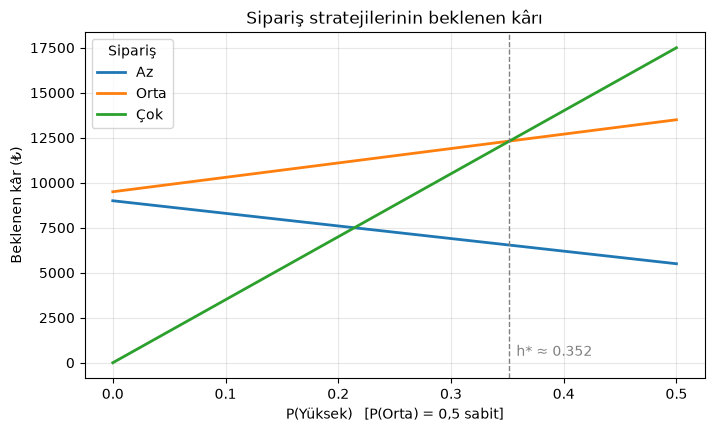

In [9]:
import matplotlib.pyplot as plt

h = np.linspace(0.0, 0.5, 200)
EU = np.array([U @ (p0 + x * dp) for x in h])

fig, ax = plt.subplots(figsize=(8, 4.5))
for j, a in enumerate(actions):
    ax.plot(h, EU[:, j], label=a, linewidth=2)
ax.axvline(h_star, color="gray", linestyle="--", linewidth=1)
ax.annotate(f"h* ≈ {h_star:.3f}", (h_star, EU.min()), xytext=(5, 5), textcoords="offset points", color="gray")
ax.set_xlabel("P(Yüksek)   [P(Orta) = 0,5 sabit]")
ax.set_ylabel("Beklenen kâr (₺)")
ax.set_title("Sipariş stratejilerinin beklenen kârı")
ax.legend(title="Sipariş")
ax.grid(alpha=0.3)
plt.show()


### İnteraktif deneme

Kaydırıcılar Jupyter içinde çalışır (`ipywidgets` gerekir). P(Orta) = 1 − P(Düşük) − P(Yüksek) olarak hesaplanır.

In [10]:
from ipywidgets import FloatSlider, interact


@interact(p_low=FloatSlider(value=0.20, min=0, max=1, step=0.01, description="P(Düşük)"),
          p_high=FloatSlider(value=0.30, min=0, max=1, step=0.01, description="P(Yüksek)"))
def simulate(p_low, p_high):
    p_mid = 1 - p_low - p_high
    if p_mid < -1e-9:
        print("P(Düşük) + P(Yüksek) 1'i geçemez.")
        return
    report([p_low, max(p_mid, 0.0), p_high])


interactive(children=(FloatSlider(value=0.2, description='P(Düşük)', max=1.0, step=0.01), FloatSlider(value=0.…